# Phần B — Vai trò của biến thêm vào

Triển khai theo [README](README.md), các hàm được định nghĩa trực tiếp trong cell.
ATE thật = 2.0; beta=(0, 0.5, 0.5), gamma=(0.5, 0.5), sigma=1 — khớp mặc định
`distribution_scenario/distribution.py` (baseline.ipynb cũ dùng tau=3 nên không copy hằng số đó).

Bản mặc định chạy **R=200** theo chế độ thử nghiệm của thiết kế. Để chạy **R=1000**,
đổi R ở cell tham số hoặc đặt `RA_VARIABLE_REPS=1000` trước khi khởi động kernel,
rồi Run All. Kết quả hiện có sẽ được ghi lại theo seed và R mới.

Phạm vi: T0–T6, V0–V5. T7, V7 và phần C là tùy chọn chưa triển khai.
Mọi PS trong estimator, balance và ESS đều là logistic **ước lượng**, không dùng PS thật.
Các CI là Wald 95%. Kết quả pilot trong README được xem là giả thuyết, không chép làm kết quả.


## 1. Tham số và thư viện
Môi trường cần numpy, pandas, scipy, statsmodels, matplotlib, IPython và Jupyter, giống các notebook mô phỏng hiện có; không thay dependency của pipeline tiền xử lý.

In [1]:
import os
import json
import warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
# Hiển thị và lưu hình ngay trong notebook khi Run All.
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TAU = 2.0
BETA = (0.0, 0.5, 0.5)
GAMMA = (0.5, 0.5)
SIGMA = 1.0
N_VALUES = (500, 2000)
R_FULL = 1000
R = int(os.environ.get("RA_VARIABLE_REPS", "200"))
SEED = 20261012
N_REF = 200_000
METHODS = ("Naive", "OLS", "IPTW", "AIPW")
Z95 = norm.ppf(0.975)
if R < 2:
    raise ValueError("Monte Carlo cần R >= 2 để tính SD và MC SE.")

# Chạy từ thư mục notebook, gốc dự án, hoặc gốc workspace.
RESULT_DIR = next((p for p in (Path.cwd(), Path.cwd() / "scenario/variable_scenario",
                              Path.cwd() / "ra_causal/scenario/variable_scenario")
                   if (p / "variable_type.ipynb").exists()), None)
if RESULT_DIR is None:
    raise FileNotFoundError("Hãy chạy kernel từ variable_scenario, ra_causal hoặc Seminar.")
RESULT_DIR = RESULT_DIR / "results"
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", None)
print(f"R={R}; n={N_VALUES}; tau={TAU}; results={RESULT_DIR}")


R=200; n=(500, 2000); tau=2.0; results=/home/doan/Seminar/ra_causal/scenario/variable_scenario/results


## 2. Cấu hình và sinh dữ liệu
Hiệu chỉnh gamma0 trên mẫu tham chiếu 200.000 quan sát độc lập cho từng kịch bản. Cache chỉ tránh tính lại cùng một DGP; không hiệu chỉnh theo từng mẫu Monte Carlo.

In [2]:
SCENARIOS = {
    "V0": dict(x2="continuous", has_x3=False, g3=0., b3=0.),
    "V1": dict(x2="continuous", has_x3=True, g3=.5, b3=.5),
    "V2": dict(x2="continuous", has_x3=True, g3=0., b3=.5),
    "V3": dict(x2="continuous", has_x3=True, g3=1., b3=0.),
    "V4": dict(x2="continuous", has_x3=True, g3=0., b3=0.),
    "V5": dict(x2="continuous", has_x3=True, g3=.5, b3=.5, rho=.7),
}
ANALYSES = {
    scenario: {"S2": {"X1": "continuous", "X2": "continuous"},
               **({"S3": {"X1": "continuous", "X2": "continuous", "X3": "continuous"}}
                  if cfg["has_x3"] else {})}
    for scenario, cfg in SCENARIOS.items()
}


In [3]:
def standardize_effect(raw, probs):
    """Tâm hóa theo xác suất tổng thể; Var đóng góp = 0.25."""
    raw, p = np.asarray(raw, float), np.asarray(probs, float)
    centered = raw - p @ raw
    return 0.5 * centered / np.sqrt(p @ centered**2)


def _draw_covariates(n, scenario, rng):
    cfg = SCENARIOS[scenario]
    x1 = rng.normal(size=n)
    if cfg["x2"] == "continuous":
        x2 = rng.normal(size=n)
        g2, h2 = GAMMA[1] * x2, BETA[2] * x2
    else:
        x2 = rng.choice(len(cfg["probs"]), size=n, p=cfg["probs"])
        h2 = standardize_effect(cfg["h"], cfg["probs"])[x2]
        g2 = (standardize_effect(cfg["g"], cfg["probs"])[x2]
              if cfg["x2"] != "rare_overlap" else np.zeros(n))
    data = {"X1": x1, "X2": x2}
    lin = GAMMA[0] * x1 + g2
    mu0 = BETA[0] + BETA[1] * x1 + h2
    if cfg.get("has_x3", False):
        rho = cfg.get("rho", 0.)
        x3 = rho * x1 + np.sqrt(1 - rho**2) * rng.normal(size=n)
        data["X3"] = x3
        lin = lin + cfg["g3"] * x3
        mu0 = mu0 + cfg["b3"] * x3
    return data, lin, mu0


def _bisect_intercept(lin, target):
    lo, hi = -50., 50.
    for _ in range(60):
        mid = (lo + hi) / 2
        if expit(mid + lin).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


@lru_cache(maxsize=None)
def _calibrate_gamma0(scenario):
    """Mẫu tham chiếu độc lập, cố định; hiệu chỉnh một lần cho từng DGP."""
    data, lin, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    cfg = SCENARIOS[scenario]
    if cfg["x2"] == "rare_overlap":
        # Hiệu chỉnh marginal e trong mức hiếm = .98 và treated toàn mẫu = .50.
        rare = data["X2"] == 2
        p_rare = rare.mean()
        target_common = (0.5 - p_rare * 0.98) / (1 - p_rare)
        gamma0 = _bisect_intercept(lin[~rare], target_common)
        rare_intercept = _bisect_intercept(lin[rare], .98)
        return gamma0, rare_intercept - gamma0
    return _bisect_intercept(lin, .5), 0.


def simulate(n, scenario, seed):
    """Seed con được truyền trực tiếp vào RNG; không dùng RNG toàn cục."""
    if scenario not in SCENARIOS or n < 4:
        raise ValueError("Kịch bản không tồn tại hoặc n < 4.")
    rng = np.random.default_rng(seed)
    data, lin, mu0 = _draw_covariates(n, scenario, rng)
    gamma0, rare_gamma = _calibrate_gamma0(scenario)
    if SCENARIOS[scenario]["x2"] == "rare_overlap":
        lin = lin + rare_gamma * (data["X2"] == 2)
    ps_true = expit(gamma0 + lin)
    a = rng.binomial(1, ps_true)
    eps = rng.normal(0, SIGMA, n)
    df = pd.DataFrame({**data, "A": a, "Y": mu0 + TAU * a + eps})
    # Truth giữ riêng; estimator/diagnostics chỉ nhận dữ liệu quan sát.
    truth = pd.DataFrame({"ps_true": ps_true, "mu0": mu0,
                          "Y0": mu0 + eps, "Y1": mu0 + eps + TAU})
    df.attrs.update(scenario=scenario, gamma0=gamma0, rare_gamma=rare_gamma)
    return df, truth


## 3. Ma trận thiết kế
Cùng design có chặn được dùng cho OLS, PS và outcome của AIPW. Dummy giữ đủ mức theo cấu hình. Với T6, ngưỡng chia nhóm là phân vị tổng thể N(0,1), giúp so sánh các cỡ mẫu trên cùng phép đo.

In [4]:
def make_design(df, spec):
    """Có chặn; dummy có đủ mức theo DGP ngay cả khi mẫu vắng một mức.

    Với T6, dùng ngưỡng phân vị N(0,1) cố định (không ước lượng lại theo mẫu).
    Các biến vắng trong spec được bỏ khỏi mọi mô hình.
    """
    out = pd.DataFrame({"const": np.ones(len(df))}, index=df.index)
    cfg = SCENARIOS[df.attrs["scenario"]]
    for col, encoding in spec.items():
        if encoding in ("continuous", "integer", "label"):
            out[col] = df[col].astype(float)
        elif encoding == "dummy" or encoding.startswith("binned_"):
            if encoding == "dummy":
                levels = range(len(cfg["probs"]))
                values = df[col]
            else:
                k = int(encoding.split("_")[1])
                levels = range(k)
                values = np.digitize(df[col], norm.ppf(np.arange(1, k) / k))
            categories = pd.Series(pd.Categorical(values, categories=levels), index=df.index)
            dummies = pd.get_dummies(categories, prefix=col, drop_first=True, dtype=float)
            out = pd.concat([out, dummies], axis=1)
        else:
            raise ValueError(f"Mã hóa không hỗ trợ: {encoding}")
    return out


def balance_design(df, spec):
    """Balance định tính luôn kiểm tra mọi dummy, kể cả khi fit bằng integer/label."""
    full_spec = dict(spec)
    cfg = SCENARIOS[df.attrs["scenario"]]
    if "X2" in spec and cfg["x2"] != "continuous":
        full_spec["X2"] = "dummy"
    out = make_design(df, full_spec).drop(columns="const")
    if "X2" in spec and cfg["x2"] != "continuous":
        # Thêm dummy mức tham chiếu để không bỏ mất mất cân bằng ở mức này.
        out["X2_0"] = (df.X2 == 0).astype(float)
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        out["X2_0"] = (np.digitize(df.X2, norm.ppf(np.arange(1, k) / k)) == 0).astype(float)
    return out


## 4. Bốn estimator và SE
Naive: Welch; OLS: HC1; IPTW Hájek: IF hiệu chỉnh ước lượng logistic; AIPW: SD của pseudo-outcome / sqrt(n). Logistic không penalize hoặc clip. Fit không xác định/hội tụ được ghi status và NaN, vẫn giữ số lần lặp yêu cầu.

In [5]:
class FitFailure(ValueError):
    pass


def _check_rank(design):
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise FitFailure("rank_deficient")


def fit_propensity(A, design):
    x = np.asarray(design, float)
    _check_rank(x)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit = sm.Logit(A, x).fit(disp=False, maxiter=100)
    if any(issubclass(w.category, PerfectSeparationWarning) for w in caught):
        raise FitFailure("perfect_separation")
    if not fit.mle_retvals.get("converged", False):
        raise FitFailure("ps_not_converged")
    e = np.asarray(fit.predict(x))
    if not np.isfinite(e).all() or np.any((e <= 0) | (e >= 1)):
        raise FitFailure("ps_at_boundary")
    # Không clip hay regularize âm thầm: T5 cần giữ trọng số cực đoan thật sự.
    return e


def est_naive(Y, A, design):
    y1, y0 = Y[A == 1], Y[A == 0]
    if min(len(y1), len(y0)) < 2:
        raise FitFailure("treatment_group_too_small")
    return y1.mean() - y0.mean(), np.sqrt(y1.var(ddof=1)/len(y1) + y0.var(ddof=1)/len(y0))


def est_ols(Y, A, design):
    x = np.column_stack([np.asarray(design), A])
    _check_rank(x)
    fit = sm.OLS(Y, x).fit(cov_type="HC1")
    return fit.params[-1], fit.bse[-1]


def est_iptw(Y, A, design, e_hat=None):
    """Hájek, IF có hiệu chỉnh score/logistic như est_iptw trong baseline.ipynb."""
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    w1, w0 = A/e, (1-A)/(1-e)
    mu1, mu0 = (w1 @ Y)/w1.sum(), (w0 @ Y)/w0.sum()
    psi = w1*(Y-mu1)/w1.mean() - w0*(Y-mu0)/w0.mean()
    a1 = x.T @ (-w1*(Y-mu1)*(1-e)) / len(Y) / w1.mean()
    a0 = x.T @ (w0*(Y-mu0)*e) / len(Y) / w0.mean()
    information = (x * (e*(1-e))[:, None]).T @ x / len(Y)
    score = x * (A-e)[:, None]
    influence = psi + score @ np.linalg.solve(information, a1-a0)
    return mu1-mu0, influence.std(ddof=1)/np.sqrt(len(Y))


def est_aipw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    predictions = {}
    for t in (0, 1):
        xt = x[A == t]
        _check_rank(xt)  # Ô rỗng: không dùng pseudoinverse để giả vờ hệ số xác định.
        if len(xt) <= x.shape[1]:
            raise FitFailure("outcome_group_too_small")
        b = np.linalg.lstsq(xt, Y[A == t], rcond=None)[0]
        predictions[t] = x @ b
    m1, m0 = predictions[1], predictions[0]
    psi = m1-m0 + A*(Y-m1)/e - (1-A)*(Y-m0)/(1-e)
    return psi.mean(), psi.std(ddof=1)/np.sqrt(len(Y))


def estimate_all(df, design):
    Y, A = df.Y.to_numpy(), df.A.to_numpy()
    estimates, status = {}, {}
    failure_types = (FitFailure, np.linalg.LinAlgError, ValueError,
                     sm.tools.sm_exceptions.PerfectSeparationError)
    def record(method, call):
        try:
            value = tuple(float(v) for v in call())
            if not np.isfinite(value).all() or value[1] < 0:
                raise FitFailure("nonfinite_estimate_or_se")
            estimates[method], status[method] = value, "ok"
        except failure_types as exc:
            estimates[method], status[method] = (np.nan, np.nan), str(exc)
    record("Naive", lambda: est_naive(Y, A, design))
    record("OLS", lambda: est_ols(Y, A, design))
    try:
        e = fit_propensity(A, design)
        ps_status = "ok"
    except failure_types as exc:
        e, ps_status = None, str(exc)
    if e is None:
        for method in ("IPTW", "AIPW"):
            estimates[method], status[method] = (np.nan, np.nan), ps_status
    else:
        record("IPTW", lambda: est_iptw(Y, A, design, e))
        record("AIPW", lambda: est_aipw(Y, A, design, e))
    return estimates, e, status, ps_status


## 5. Kiểm tra và chẩn đoán từng kịch bản
SMD nhị phân/dummy dùng mẫu số từ tỷ lệ từng nhóm; biến liên tục dùng mẫu số trước weighting. Không tính VR cho dummy. Balance định tính kiểm tra cả mức tham chiếu và mọi dummy, kể cả analysis dùng integer/label.

In [6]:
def cell_counts(df, spec):
    cfg = SCENARIOS[df.attrs["scenario"]]
    if cfg["x2"] != "continuous":
        values, levels = df.X2, range(len(cfg["probs"]))
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        values, levels = np.digitize(df.X2, norm.ppf(np.arange(1, k)/k)), range(k)
    else:
        return pd.DataFrame()
    return pd.crosstab(df.A, pd.Series(np.asarray(values), index=df.index, name="X2_level")) \
             .reindex(index=[0, 1], columns=list(levels), fill_value=0)


def smd_table(covariates, A, weights=None):
    w = np.ones(len(A)) if weights is None else np.asarray(weights)
    rows = []
    for col in covariates:
        x = covariates[col].to_numpy(float)
        m1 = np.average(x[A == 1], weights=w[A == 1])
        m0 = np.average(x[A == 0], weights=w[A == 0])
        binary = np.isin(x, [0., 1.]).all()
        if binary:
            denom = np.sqrt((m1*(1-m1) + m0*(1-m0))/2)
        else:
            # Dénominateur avant weighting, identique avant/après pour continu.
            denom = np.sqrt((x[A == 1].var(ddof=1)+x[A == 0].var(ddof=1))/2)
        smd = (m1-m0)/denom if denom > 0 else (0. if m1 == m0 else np.inf)
        rows.append({"variable": col, "kind": "binary" if binary else "continuous", "smd": smd})
    return pd.DataFrame(rows).set_index("variable")


def diagnostics(df, spec, e):
    A = df.A.to_numpy()
    counts = cell_counts(df, spec)
    covs = balance_design(df, spec)
    before = smd_table(covs, A)
    result = {"treated_rate": A.mean(), "empty_cells": int((counts == 0).sum().sum()),
              "has_empty_cell": bool((counts == 0).any().any()) if not counts.empty else False,
              "min_cell_count": counts.to_numpy().min() if not counts.empty else np.nan,
              "cell_counts": counts.to_json() if not counts.empty else "{}",
              "max_abs_smd_before": before.smd.abs().max(),
              "e_min": np.nan, "e_max": np.nan, "e_outside": np.nan,
              "max_weight": np.nan, "ess_ratio": np.nan,
              "ess_treated_ratio": np.nan, "ess_control_ratio": np.nan,
              "max_abs_smd_after": np.nan, "x3_smd_after": np.nan,
              "x2_continuous_smd_after": np.nan}
    if e is not None:
        w = A/e + (1-A)/(1-e)
        result.update(e_min=e.min(), e_max=e.max(),
                      e_outside=np.mean((e < .01) | (e > .99)), max_weight=w.max(),
                      ess_ratio=w.sum()**2/(w @ w)/len(w),
                      max_abs_smd_after=smd_table(covs, A, w).smd.abs().max())
        for t, name in ((1, "treated"), (0, "control")):
            wt = w[A == t]
            result[f"ess_{name}_ratio"] = wt.sum()**2/(wt @ wt)/len(wt)
        # Diagnostics de simulation: variable omise disponible au chercheur seulement.
        if "X3" in df:
            result["x3_smd_after"] = smd_table(df[["X3"]], A, w).smd.iloc[0]
        if df.attrs["scenario"] == "T6":
            result["x2_continuous_smd_after"] = smd_table(df[["X2"]], A, w).smd.iloc[0]
    return result


def inspect_case(scenario, n=2000, seed=SEED):
    df, _ = simulate(n, scenario, seed)
    print(f"{scenario}: n={n}, gamma0={df.attrs['gamma0']:.4f}, ATE={TAU}")
    specs = ANALYSES[scenario]
    fig, axes = plt.subplots(1, len(specs), figsize=(max(6, 3*len(specs)), 2.8), squeeze=False)
    for ax, (analysis, spec) in zip(axes[0], specs.items()):
        design = make_design(df, spec)
        estimates, e, status, ps_status = estimate_all(df, design)
        counts = cell_counts(df, spec)
        display(Markdown(f"**{analysis}**"))
        if not counts.empty:
            display(counts)
        display(pd.DataFrame([{"method": m, "est": estimates[m][0], "se": estimates[m][1],
                               "status": status[m]} for m in METHODS]))
        diag = diagnostics(df, spec, e)
        display(pd.DataFrame([{k: v for k, v in diag.items() if k != "cell_counts"}]))
        covs = balance_design(df, spec)
        table = smd_table(covs, df.A.to_numpy()).rename(columns={"smd": "smd_before"})
        if e is not None:
            A = df.A.to_numpy()
            table["smd_after"] = smd_table(covs, A, A/e+(1-A)/(1-e)).smd
            for t in (0, 1):
                ax.hist(e[A == t], bins=np.linspace(0, 1, 31), alpha=.5, label=f"A={t}")
        else:
            ax.text(.5, .5, ps_status, ha="center", transform=ax.transAxes)
        display(table)
        ax.set(title=analysis, xlabel="Propensity score ước lượng", xlim=(0, 1))
        if e is not None:
            ax.legend(frameon=False)
    fig.suptitle(scenario)
    fig.tight_layout()
    plt.show()


In [7]:
# Kiểm tra tính tái lập, consistency, chặn và các SE trên baseline.
baseline = next(iter(SCENARIOS))
d1, t1 = simulate(500, baseline, 42)
d2, t2 = simulate(500, baseline, 42)
pd.testing.assert_frame_equal(d1, d2)
pd.testing.assert_frame_equal(t1, t2)
d3, _ = simulate(500, baseline, 43)
assert not d1.equals(d3)
np.testing.assert_allclose(t1.Y1-t1.Y0, TAU)
np.testing.assert_allclose(d1.Y, np.where(d1.A == 1, t1.Y1, t1.Y0))
for scenario, cfg in SCENARIOS.items():
    d, _ = simulate(500, scenario, 42)
    for spec in ANALYSES[scenario].values():
        design = make_design(d, spec)
        assert np.all(design.iloc[:, 0] == 1) and design.columns.is_unique
    if "g" in cfg:
        for effect in (cfg["g"], cfg["h"]):
            e = standardize_effect(effect, cfg["probs"])
            np.testing.assert_allclose(np.dot(cfg["probs"], e), 0, atol=1e-12)
            np.testing.assert_allclose(np.dot(cfg["probs"], e**2), .25)
x = make_design(d1, next(iter(ANALYSES[baseline].values())))
est, ps, status, _ = estimate_all(d1, x)
assert all(s == "ok" for s in status.values())
reference = sm.OLS(d1.Y, np.column_stack([x, d1.A])).fit(cov_type="HC1")
np.testing.assert_allclose(est["OLS"], [reference.params.iloc[-1], reference.bse.iloc[-1]])
# SMD nhị phân theo đúng công thức tỷ lệ, không dùng VR.
binary = pd.DataFrame({"dummy": [0, 0, 1, 0, 1, 1]})
a = np.array([0, 0, 0, 1, 1, 1])
np.testing.assert_allclose(smd_table(binary, a).smd.iloc[0], (2/3-1/3)/np.sqrt(2/9))
print("Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS")

# Đối chiếu SE IPTW với sandwich của hệ estimating equations chung,
# dùng đạo hàm số độc lập để kiểm tra dấu hiệu chỉnh và chuẩn hóa Hájek.
df_check, _ = simulate(2000, baseline, 113)
x_check = make_design(df_check, next(iter(ANALYSES[baseline].values()))).to_numpy()
y_check, a_check = df_check.Y.to_numpy(), df_check.A.to_numpy()
ps_fit = sm.Logit(a_check, x_check).fit(disp=False)
e_check = ps_fit.predict(x_check)
w1_check, w0_check = a_check/e_check, (1-a_check)/(1-e_check)
mu1_check = (w1_check @ y_check)/w1_check.sum()
mu0_check = (w0_check @ y_check)/w0_check.sum()
theta_check = np.r_[ps_fit.params, mu1_check, mu0_check]
def joint_equations(theta):
    prob = expit(x_check @ theta[:-2])
    return np.column_stack([x_check*(a_check-prob)[:, None],
                            a_check/prob*(y_check-theta[-2]),
                            (1-a_check)/(1-prob)*(y_check-theta[-1])])
step = 1e-5
eye_check = np.eye(len(theta_check))
jacobian = np.column_stack([
    (joint_equations(theta_check + eye_check[j]*step).mean(0)
     - joint_equations(theta_check - eye_check[j]*step).mean(0))/(2*step)
    for j in range(len(theta_check))])
joint_if = np.linalg.solve(jacobian, -joint_equations(theta_check).T).T
sandwich_se = (joint_if[:, -2]-joint_if[:, -1]).std(ddof=1)/np.sqrt(len(y_check))
np.testing.assert_allclose(est_iptw(y_check, a_check, x_check, e_check),
                           [mu1_check-mu0_check, sandwich_se], rtol=1e-7)
# Kiểm tra trực tiếp gamma0 trên đúng mẫu tham chiếu, bao gồm e≈.98 ở T5.
for scenario, cfg in SCENARIOS.items():
    data_check, lin_check, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    g0_check, rare_check = _calibrate_gamma0(scenario)
    if cfg["x2"] == "rare_overlap":
        lin_check = lin_check + rare_check*(data_check["X2"] == 2)
    prob_check = expit(g0_check+lin_check)
    np.testing.assert_allclose(prob_check.mean(), .5, atol=1e-10)
    if cfg["x2"] == "rare_overlap":
        np.testing.assert_allclose(prob_check[data_check["X2"] == 2].mean(), .98, atol=1e-10)
child_check = np.random.SeedSequence(7).spawn(2)
child_df0, _ = simulate(500, baseline, child_check[0])
child_df0_again, _ = simulate(500, baseline, child_check[0])
child_df1, _ = simulate(500, baseline, child_check[1])
pd.testing.assert_frame_equal(child_df0, child_df0_again)
assert not child_df0.equals(child_df1)
print("Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS")


Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS
Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS


### V0
**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, coverage gần 0.95.

V0: n=2000, gamma0=-0.0012, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.422115,0.054261,ok
1,OLS,2.005205,0.047065,ok
2,IPTW,2.016445,0.047854,ok
3,AIPW,2.001927,0.046930,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.4995,0,False,NaN,0.452118,0.098221,0.910953,0.0,6.25272,0.906337,0.901605,0.911206,0.025039,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.379860,0.005472
X2,continuous,0.452118,0.025039


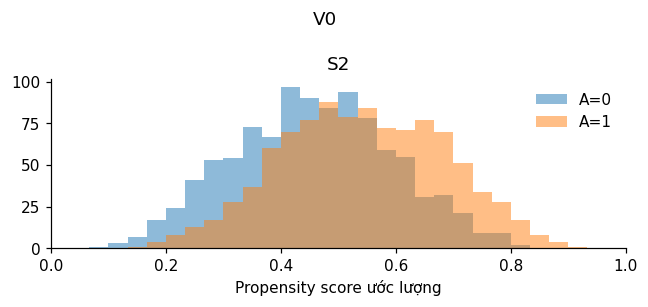

In [8]:
inspect_case("V0")

### V1
**Kỳ vọng:** S2 chệch; S3 gần không chệch dù balance S2 nhìn tốt.

V1: n=2000, gamma0=-0.0028, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.715607,0.058139,ok
1,OLS,2.261939,0.053003,ok
2,IPTW,2.262172,0.053373,ok
3,AIPW,2.257014,0.053010,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.501,0,False,NaN,0.492026,0.072104,0.939229,0.0,12.372787,0.863183,0.855091,0.871419,0.007469,0.474967,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.456262,0.002546
X2,continuous,0.492026,0.007469


**S3**

,method,est,se,status
0,Naive,2.715607,0.058139,ok
1,OLS,2.037368,0.048408,ok
2,IPTW,2.060066,0.049405,ok
3,AIPW,2.037987,0.048343,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.501,0,False,NaN,0.492026,0.024904,0.974348,0.0,14.536769,0.809958,0.812392,0.807627,0.025573,0.007006,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.456262,0.012099
X2,continuous,0.492026,0.025573
X3,continuous,0.410931,0.007006


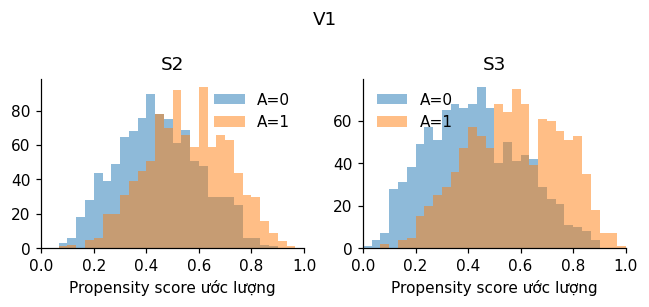

In [9]:
inspect_case("V1")

### V2
**Kỳ vọng:** S3 giảm SD so với S2 nhờ biến tiên lượng Y.

V2: n=2000, gamma0=-0.0012, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.477662,0.059370,ok
1,OLS,1.976357,0.053367,ok
2,IPTW,1.977214,0.054406,ok
3,AIPW,1.972795,0.053316,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.503,0,False,NaN,0.514587,0.063943,0.947869,0.0,13.637742,0.852285,0.852709,0.852067,0.011051,0.002568,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.514587,0.001246
X2,continuous,0.466855,0.011051


**S3**

,method,est,se,status
0,Naive,2.477662,0.059370,ok
1,OLS,1.977598,0.047881,ok
2,IPTW,1.977720,0.048947,ok
3,AIPW,1.970444,0.047896,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.503,0,False,NaN,0.514587,0.063918,0.947845,0.0,13.636221,0.852291,0.852655,0.85213,0.011018,0.00362,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.514587,0.001269
X2,continuous,0.466855,0.011018
X3,continuous,-0.000570,0.003620


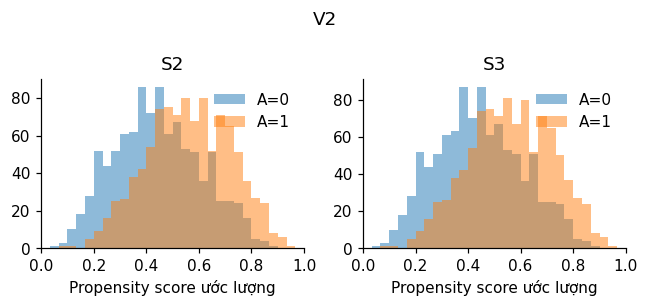

In [10]:
inspect_case("V2")

### V3
**Kỳ vọng:** S3 có thể tăng SD và giảm ESS, rõ hơn ở IPTW.

V3: n=2000, gamma0=-0.0042, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.464009,0.054923,ok
1,OLS,2.039277,0.047332,ok
2,IPTW,2.038320,0.047420,ok
3,AIPW,2.027122,0.047237,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.496,0,False,NaN,0.43743,0.096392,0.912937,0.0,9.401534,0.900308,0.89203,0.909272,0.010186,0.865325,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.401826,0.010186
X2,continuous,0.437430,0.009921


**S3**

,method,est,se,status
0,Naive,2.464009,0.054923,ok
1,OLS,2.026675,0.050584,ok
2,IPTW,2.059932,0.052968,ok
3,AIPW,2.027322,0.052038,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.496,0,False,NaN,0.787265,0.008525,0.994532,0.001,17.856138,0.692451,0.716478,0.670558,0.047827,0.015645,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.401826,0.020247
X2,continuous,0.437430,0.047827
X3,continuous,0.787265,0.015645


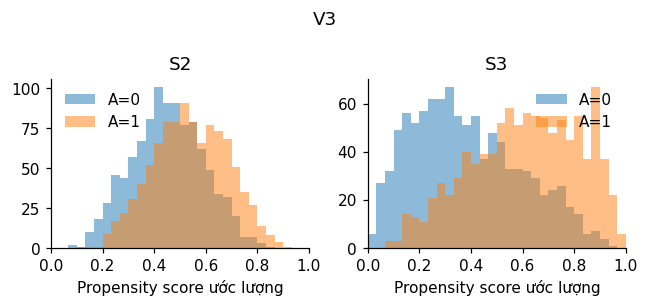

In [11]:
inspect_case("V3")

### V4
**Kỳ vọng:** Hai tập biến gần như tương đương; biến noise có chi phí hữu hạn mẫu.

V4: n=2000, gamma0=-0.0012, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.477938,0.054893,ok
1,OLS,1.977547,0.047866,ok
2,IPTW,1.975972,0.048621,ok
3,AIPW,1.971325,0.047898,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.503,0,False,NaN,0.514587,0.063943,0.947869,0.0,13.637742,0.852285,0.852709,0.852067,0.011051,0.002568,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.514587,0.001246
X2,continuous,0.466855,0.011051


**S3**

,method,est,se,status
0,Naive,2.477938,0.054893,ok
1,OLS,1.977598,0.047881,ok
2,IPTW,1.975970,0.048622,ok
3,AIPW,1.970444,0.047896,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.503,0,False,NaN,0.514587,0.063918,0.947845,0.0,13.636221,0.852291,0.852655,0.85213,0.011018,0.00362,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.514587,0.001269
X2,continuous,0.466855,0.011018
X3,continuous,-0.000570,0.003620


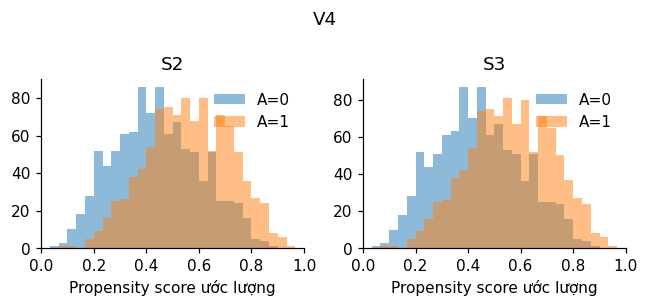

In [12]:
inspect_case("V4")

### V5
**Kỳ vọng:** Bỏ X3 vẫn chệch nhưng ít hơn V1; S3 gần không chệch.

V5: n=2000, gamma0=-0.0029, ATE=2.0


**S2**

,method,est,se,status
0,Naive,2.952686,0.062837,ok
1,OLS,2.102194,0.051874,ok
2,IPTW,2.080855,0.062575,ok
3,AIPW,2.100372,0.052058,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.513,0,False,NaN,0.790085,0.026617,0.982044,0.0,29.045035,0.707576,0.686071,0.730268,0.020714,0.183409,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.790085,-0.020714
X2,continuous,0.429117,-0.007680


**S3**

,method,est,se,status
0,Naive,2.952686,0.062837,ok
1,OLS,2.010551,0.049145,ok
2,IPTW,1.998780,0.062529,ok
3,AIPW,2.011776,0.049345,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.513,0,False,NaN,0.790085,0.017331,0.985058,0.0,31.447233,0.681826,0.661617,0.703117,0.027127,-0.011214,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.790085,-0.027127
X2,continuous,0.429117,0.007983
X3,continuous,0.716430,-0.011214


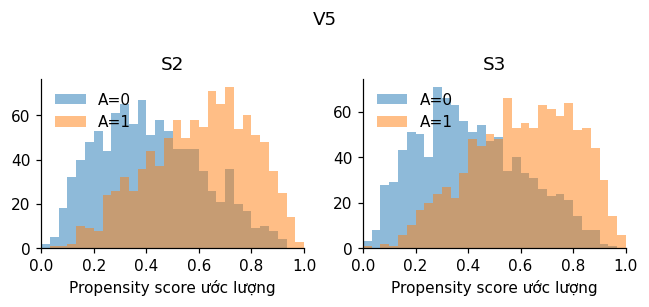

In [13]:
inspect_case("V5")

## 6. Monte Carlo và lưu dữ liệu
`SeedSequence([seed, mã_kịch_bản, n]).spawn(R)` tạo seed con và truyền vào `simulate`. Các analysis của cùng rep dùng cùng dữ liệu. CSV raw có khóa scenario/analysis/n/rep/method; diagnostics lưu riêng một dòng/analysis/rep, bao gồm bảng đếm các ô định tính dạng JSON.

In [14]:
def run_mc(R=R, seed=SEED, scenarios=None, n_values=N_VALUES):
    if R < 2:
        raise ValueError("R phải >= 2.")
    selected = list(SCENARIOS) if scenarios is None else list(scenarios)
    # Cùng rep dùng cùng dữ liệu cho mọi analysis, tạo so sánh ghép cặp.
    # Mã seed ổn định theo scenario/n; không phụ thuộc thứ tự chạy/lọc scenario.
    all_rows, all_diagnostics = [], []
    for scenario in selected:
        scenario_rows, scenario_diagnostics = [], []
        sizes = tuple(n_values) + ((8000,) if scenario == "T6" and 8000 not in n_values else ())
        for n in sizes:
            code = sum((i+1)*ord(c) for i, c in enumerate(scenario))
            children = np.random.SeedSequence([seed, code, n]).spawn(R)
            for rep, child in enumerate(children):
                df, _ = simulate(n, scenario, child)
                for analysis, spec in ANALYSES[scenario].items():
                    design = make_design(df, spec)
                    estimates, e, status, ps_status = estimate_all(df, design)
                    key = dict(scenario=scenario, analysis=analysis, n=n, rep=rep)
                    for method, (est, se) in estimates.items():
                        scenario_rows.append({**key, "method": method, "est": est, "se": se,
                                              "truth": TAU, "status": status[method]})
                    scenario_diagnostics.append({**key, "ps_status": ps_status,
                                                 **diagnostics(df, spec, e)})
            print(f"{scenario}, n={n}: {R} lần lặp hoàn tất", flush=True)
        # Lưu raw trước khi tóm tắt; một dòng/method/rep dù fit thất bại.
        rows, diags = pd.DataFrame(scenario_rows), pd.DataFrame(scenario_diagnostics)
        rows.to_csv(RESULT_DIR / f"{scenario}.csv", index=False)
        diags.to_csv(RESULT_DIR / f"{scenario}_diagnostics.csv", index=False)
        all_rows.append(rows)
        all_diagnostics.append(diags)
    return pd.concat(all_rows, ignore_index=True), pd.concat(all_diagnostics, ignore_index=True)


def summarize_mc(raw):
    rows = []
    for key, group in raw.groupby(["scenario", "analysis", "n", "method"], sort=False):
        ok = group.status.eq("ok") & np.isfinite(group.est) & np.isfinite(group.se)
        valid = group.loc[ok]
        est, se = valid.est.to_numpy(), valid.se.to_numpy()
        truth = valid.truth.to_numpy()
        sd = est.std(ddof=1) if len(est) > 1 else np.nan
        coverage = np.mean(np.abs(est-truth) <= Z95*se) if len(est) else np.nan
        rows.append({**dict(zip(("scenario", "analysis", "n", "method"), key)),
                     "R": len(group), "valid_reps": len(valid), "failed_reps": int((~ok).sum()),
                     "failure_rate": (~ok).mean(),
                     "bias": np.mean(est-truth) if len(est) else np.nan,
                     "mc_se_bias": sd/np.sqrt(len(est)) if len(est) else np.nan,
                     "emp_sd": sd, "mean_se": se.mean() if len(est) else np.nan,
                     "se_sd_ratio": se.mean()/sd if sd > 0 else np.nan,
                     "rmse": np.sqrt(np.mean((est-truth)**2)) if len(est) else np.nan,
                     "coverage": coverage,
                     "mc_se_coverage": np.sqrt(coverage*(1-coverage)/len(est)) if len(est) else np.nan,
                     "mean_ci_width": 2*Z95*se.mean() if len(est) else np.nan})
    return pd.DataFrame(rows)


def summarize_diagnostics(diags):
    grouped = diags.groupby(["scenario", "analysis", "n"], sort=False)
    means = grouped[["treated_rate", "e_min", "e_max", "e_outside", "max_weight", "ess_ratio",
                     "ess_treated_ratio", "ess_control_ratio", "max_abs_smd_before",
                     "max_abs_smd_after", "x3_smd_after", "x2_continuous_smd_after"]].mean()
    means["R"] = grouped.size()
    means["ps_valid_reps"] = grouped.ps_status.apply(lambda s: s.eq("ok").sum())
    means["ps_failed_reps"] = grouped.ps_status.apply(lambda s: s.ne("ok").sum())
    means["empty_cell_reps"] = grouped.has_empty_cell.sum()
    means["empty_cell_rate"] = grouped.has_empty_cell.mean()
    means["min_cell_count_observed"] = grouped.min_cell_count.min()
    return means.reset_index()


def save_metadata(part):
    metadata = {"part": part, "R": R, "R_full": R_FULL, "seed": SEED, "n": list(N_VALUES),
                "T6_extra_n": 8000 if part == "A" else None, "tau": TAU,
                "beta": BETA, "gamma": GAMMA, "sigma": SIGMA, "n_ref": N_REF,
                "calibration_seed": 12345, "bin_cutpoints": "population N(0,1) quantiles",
                "ps": "unpenalized estimated logistic, no clipping",
                "versions": {"numpy": np.__version__, "pandas": pd.__version__,
                             "scipy": scipy.__version__, "statsmodels": statsmodels.__version__},
                "gamma0": {s: _calibrate_gamma0(s)[0] for s in SCENARIOS},
                "rare_gamma": {s: _calibrate_gamma0(s)[1] for s in SCENARIOS}}
    (RESULT_DIR / f"part_{part}_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")


In [15]:
raw, diagnostic_raw = run_mc()
save_metadata("B")
print(f"Đã lưu {len(raw):,} dòng ước lượng; {len(diagnostic_raw):,} dòng diagnostics.")

V0, n=500: 200 lần lặp hoàn tất


V0, n=2000: 200 lần lặp hoàn tất


V1, n=500: 200 lần lặp hoàn tất


V1, n=2000: 200 lần lặp hoàn tất


V2, n=500: 200 lần lặp hoàn tất


V2, n=2000: 200 lần lặp hoàn tất


... (3 outputs left out)

V4, n=2000: 200 lần lặp hoàn tất


V5, n=500: 200 lần lặp hoàn tất


V5, n=2000: 200 lần lặp hoàn tất


Đã lưu 17,600 dòng ước lượng; 4,400 dòng diagnostics.


## 7. Tóm tắt từ CSV
Đọc lại raw đã lưu để có thể tính lại metrics mà không chạy mô phỏng. `valid_reps`, `failed_reps`, `failure_rate` nêu mẫu số; bias, SD, SE, RMSE và coverage tính trên các lần thành công. Khi có failure, coverage này là coverage có điều kiện và cần đọc cùng failure rate. `mc_se_bias=SD/sqrt(valid_reps)`; thêm MC SE của coverage để diễn giải dao động Monte Carlo.

In [15]:
raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}.csv") for s in SCENARIOS], ignore_index=True)
diagnostic_raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}_diagnostics.csv") for s in SCENARIOS], ignore_index=True)
summary = summarize_mc(raw)
diagnostic_summary = summarize_diagnostics(diagnostic_raw)
summary.to_csv(RESULT_DIR / "part_B_summary.csv", index=False)
diagnostic_summary.to_csv(RESULT_DIR / "part_B_diagnostic_summary.csv", index=False)
display(summary.round(4))
display(diagnostic_summary.round(4))
# Kiểm tra đầy đủ khóa và số dòng sau khi đọc lại CSV.
assert not raw.duplicated(["scenario", "analysis", "n", "rep", "method"]).any()
assert not diagnostic_raw.duplicated(["scenario", "analysis", "n", "rep"]).any()
assert raw.groupby(["scenario", "analysis", "n", "rep"]).size().eq(len(METHODS)).all()
assert summary.R.eq(R).all()
assert (summary.valid_reps + summary.failed_reps).eq(R).all()
assert summary.valid_reps.eq(raw[raw.status.eq("ok")].groupby(
    ["scenario", "analysis", "n", "method"], sort=False).size().to_numpy()).all()
print("Kiểm tra CSV: khóa duy nhất, đủ method/rep và failure count: PASS")


,scenario,analysis,n,method,R,valid_reps,failed_reps,failure_rate,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,rmse,coverage,mc_se_coverage,mean_ci_width
0,V0,S2,500,Naive,200,200,0,0.0,0.4609,0.0078,0.1110,0.1076,0.9693,0.4740,0.015,0.0086,0.4218
1,V0,S2,500,OLS,200,200,0,0.0,0.0118,0.0068,0.0965,0.0948,0.9832,0.0969,0.930,0.0180,0.3717
2,V0,S2,500,IPTW,200,200,0,0.0,0.0141,0.0071,0.1010,0.0979,0.9690,0.1017,0.930,0.0180,0.3837
3,V0,S2,500,AIPW,200,200,0,0.0,0.0124,0.0071,0.0999,0.0960,0.9608,0.1005,0.930,0.0180,0.3764
4,V0,S2,2000,Naive,200,200,0,0.0,0.4511,0.0036,0.0516,0.0539,1.0448,0.4540,0.000,0.0000,0.2112
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,V5,S2,2000,AIPW,200,200,0,0.0,0.1200,0.0039,0.0557,0.0541,0.9716,0.1322,0.395,0.0346,0.2120
84,V5,S3,2000,Naive,200,200,0,0.0,0.8938,0.0043,0.0615,0.0617,1.0028,0.8959,0.000,0.0000,0.2417
85,V5,S3,2000,OLS,200,200,0,0.0,-0.0008,0.0036,0.0510,0.0495,0.9701,0.0509,0.965,0.0130,0.1939
86,V5,S3,2000,IPTW,200,200,0,0.0,-0.0072,0.0047,0.0666,0.0628,0.9424,0.0668,0.935,0.0174,0.2460


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
0,V0,S2,500,0.5005,0.1065,0.8965,0.0000,7.7533,0.8664,0.8710,0.8678,0.5128,0.0266,NaN,NaN,200,200,0,0,0.0,NaN
1,V0,S2,2000,0.4992,0.0817,0.9151,0.0000,9.2132,0.8742,0.8746,0.8754,0.4873,0.0117,NaN,NaN,200,200,0,0,0.0,NaN
2,V1,S2,500,0.5001,0.1161,0.8835,0.0000,7.1299,0.8796,0.8822,0.8826,0.5001,0.0241,0.4817,NaN,200,200,0,0,0.0,NaN
3,V1,S3,500,0.5001,0.0678,0.9294,0.0000,10.4765,0.8037,0.8067,0.8116,0.5223,0.0427,0.0019,NaN,200,200,0,0,0.0,NaN
4,V1,S2,2000,0.5004,0.0905,0.9098,0.0000,8.7309,0.8844,0.8858,0.8846,0.4707,0.0108,0.4850,NaN,200,200,0,0,0.0,NaN
5,V1,S3,2000,0.5004,0.0503,0.9494,0.0000,13.6228,0.8093,0.8121,0.8094,0.4808,0.0204,-0.0007,NaN,200,200,0,0,0.0,NaN
6,V2,S2,500,0.4988,0.1068,0.8883,0.0000,7.7074,0.8678,0.8701,0.8722,0.5116,0.0273,0.0007,NaN,200,200,0,0,0.0,NaN
7,V2,S3,500,0.4988,0.1056,0.8899,0.0000,7.8663,0.8653,0.8680,0.8696,0.5116,0.0292,-0.0000,NaN,200,200,0,0,0.0,NaN
8,V2,S2,2000,0.4999,0.0818,0.9173,0.0000,9.3465,0.8745,0.8754,0.8750,0.4841,0.0121,-0.0020,NaN,200,200,0,0,0.0,NaN
9,V2,S3,2000,0.4999,0.0814,0.9176,0.0000,9.4070,0.8736,0.8745,0.8742,0.4841,0.0132,-0.0003,NaN,200,200,0,0,0.0,NaN


Kiểm tra CSV: khóa duy nhất, đủ method/rep và failure count: PASS


In [16]:
# Mốc baseline: Naive dự kiến chệch nên chỉ kiểm tra estimator điều chỉnh.
base = summary[(summary.scenario == next(iter(SCENARIOS))) & (summary.method != "Naive")].copy()
base["bias_within_3_mc_se"] = base.bias.abs() <= 3*base.mc_se_bias
base["coverage_near_95"] = (base.coverage-.95).abs() <= 3*np.sqrt(.95*.05/base.valid_reps)
base["se_sd_near_1"] = base.se_sd_ratio.between(.8, 1.2)
display(base[["n", "method", "bias", "mc_se_bias", "coverage", "se_sd_ratio",
              "bias_within_3_mc_se", "coverage_near_95", "se_sd_near_1"]].round(4))
assert base.failed_reps.eq(0).all()
assert base.bias_within_3_mc_se.all() and base.coverage_near_95.all() and base.se_sd_near_1.all()
print("Baseline Monte Carlo: PASS (dung sai theo MC SE, không ép bias bằng 0).")

,n,method,bias,mc_se_bias,coverage,se_sd_ratio,bias_within_3_mc_se,coverage_near_95,se_sd_near_1
1,500,OLS,0.0118,0.0068,0.930,0.9832,True,True,True
2,500,IPTW,0.0141,0.0071,0.930,0.9690,True,True,True
3,500,AIPW,0.0124,0.0071,0.930,0.9608,True,True,True
5,2000,OLS,0.0008,0.0032,0.955,1.0351,True,True,True
6,2000,IPTW,0.0014,0.0034,0.975,1.0204,True,True,True
7,2000,AIPW,0.0005,0.0033,0.950,1.0149,True,True,True


Baseline Monte Carlo: PASS (dung sai theo MC SE, không ép bias bằng 0).


## 8. Kỳ vọng → Kết quả → Giải thích
Các bảng dưới được sinh từ kết quả thực tế của lần chạy, không suy diễn từ pilot. So sánh độ chệch với MC SE; chênh lệch nhỏ ở R=200 cần xác nhận bằng R=1000.

In [17]:
display(Markdown("### V0\n**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, coverage gần 0.95.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V0"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V0")].round(4))
display(Markdown("**Giải thích:** Mốc hai confounder liên tục, dùng cùng tham số với T0."))

### V0
**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, coverage gần 0.95.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
0,S2,500,Naive,0.4609,0.0078,0.1110,0.1076,0.9693,0.015,0.0086,0
1,S2,500,OLS,0.0118,0.0068,0.0965,0.0948,0.9832,0.930,0.0180,0
2,S2,500,IPTW,0.0141,0.0071,0.1010,0.0979,0.9690,0.930,0.0180,0
3,S2,500,AIPW,0.0124,0.0071,0.0999,0.0960,0.9608,0.930,0.0180,0
4,S2,2000,Naive,0.4511,0.0036,0.0516,0.0539,1.0448,0.000,0.0000,0
5,S2,2000,OLS,0.0008,0.0032,0.0456,0.0472,1.0351,0.955,0.0147,0
6,S2,2000,IPTW,0.0014,0.0034,0.0478,0.0488,1.0204,0.975,0.0110,0
7,S2,2000,AIPW,0.0005,0.0033,0.0470,0.0477,1.0149,0.950,0.0154,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
0,V0,S2,500,0.5005,0.1065,0.8965,0.0,7.7533,0.8664,0.8710,0.8678,0.5128,0.0266,NaN,NaN,200,200,0,0,0.0,NaN
1,V0,S2,2000,0.4992,0.0817,0.9151,0.0,9.2132,0.8742,0.8746,0.8754,0.4873,0.0117,NaN,NaN,200,200,0,0,0.0,NaN


**Giải thích:** Mốc hai confounder liên tục, dùng cùng tham số với T0.

In [18]:
display(Markdown("### V1\n**Kỳ vọng:** S2 chệch; S3 gần không chệch dù balance S2 nhìn tốt.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V1"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V1")].round(4))
display(Markdown("**Giải thích:** X3 là confounder bị bỏ sót. Cột x3_smd_after là chẩn đoán mô phỏng, không khả dụng khi X3 không quan sát trong thực tế."))

### V1
**Kỳ vọng:** S2 chệch; S3 gần không chệch dù balance S2 nhìn tốt.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
8,S2,500,Naive,0.6538,0.0083,0.1180,0.1150,0.9740,0.000,0.0000,0
9,S2,500,OLS,0.2412,0.0075,0.1058,0.1048,0.9906,0.390,0.0345,0
10,S2,500,IPTW,0.2449,0.0076,0.1076,0.1073,0.9972,0.360,0.0339,0
11,S2,500,AIPW,0.2415,0.0075,0.1061,0.1056,0.9955,0.385,0.0344,0
12,S3,500,Naive,0.6538,0.0083,0.1180,0.1150,0.9740,0.000,0.0000,0
13,S3,500,OLS,0.0035,0.0070,0.0995,0.0966,0.9708,0.950,0.0154,0
14,S3,500,IPTW,0.0082,0.0080,0.1133,0.1050,0.9267,0.930,0.0180,0
15,S3,500,AIPW,0.0039,0.0076,0.1069,0.0992,0.9278,0.930,0.0180,0
16,S2,2000,Naive,0.6487,0.0040,0.0572,0.0574,1.0022,0.000,0.0000,0
17,S2,2000,OLS,0.2364,0.0037,0.0520,0.0523,1.0056,0.020,0.0099,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
2,V1,S2,500,0.5001,0.1161,0.8835,0.0,7.1299,0.8796,0.8822,0.8826,0.5001,0.0241,0.4817,NaN,200,200,0,0,0.0,NaN
3,V1,S3,500,0.5001,0.0678,0.9294,0.0,10.4765,0.8037,0.8067,0.8116,0.5223,0.0427,0.0019,NaN,200,200,0,0,0.0,NaN
4,V1,S2,2000,0.5004,0.0905,0.9098,0.0,8.7309,0.8844,0.8858,0.8846,0.4707,0.0108,0.4850,NaN,200,200,0,0,0.0,NaN
5,V1,S3,2000,0.5004,0.0503,0.9494,0.0,13.6228,0.8093,0.8121,0.8094,0.4808,0.0204,-0.0007,NaN,200,200,0,0,0.0,NaN


**Giải thích:** X3 là confounder bị bỏ sót. Cột x3_smd_after là chẩn đoán mô phỏng, không khả dụng khi X3 không quan sát trong thực tế.

In [19]:
display(Markdown("### V2\n**Kỳ vọng:** S3 giảm SD so với S2 nhờ biến tiên lượng Y.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V2"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V2")].round(4))
display(Markdown("**Giải thích:** X3 độc lập cơ chế điều trị nhưng giải thích một phần phương sai outcome."))

### V2
**Kỳ vọng:** S3 giảm SD so với S2 nhờ biến tiên lượng Y.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
24,S2,500,Naive,0.4494,0.0082,0.1166,0.1170,1.0029,0.015,0.0086,0
25,S2,500,OLS,-0.0005,0.0072,0.1021,0.1057,1.0358,0.965,0.0130,0
26,S2,500,IPTW,0.0018,0.0073,0.1026,0.1084,1.0559,0.960,0.0139,0
27,S2,500,AIPW,0.0018,0.0073,0.1034,0.1074,1.0386,0.960,0.0139,0
28,S3,500,Naive,0.4494,0.0082,0.1166,0.1170,1.0029,0.015,0.0086,0
29,S3,500,OLS,-0.0009,0.0069,0.0974,0.0945,0.9710,0.925,0.0186,0
30,S3,500,IPTW,0.0015,0.0071,0.1000,0.0978,0.9774,0.935,0.0174,0
31,S3,500,AIPW,0.0016,0.0070,0.0995,0.0959,0.9642,0.925,0.0186,0
32,S2,2000,Naive,0.4478,0.0039,0.0557,0.0583,1.0466,0.000,0.0000,0
33,S2,2000,OLS,-0.0001,0.0036,0.0507,0.0527,1.0390,0.970,0.0121,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
6,V2,S2,500,0.4988,0.1068,0.8883,0.0,7.7074,0.8678,0.8701,0.8722,0.5116,0.0273,0.0007,NaN,200,200,0,0,0.0,NaN
7,V2,S3,500,0.4988,0.1056,0.8899,0.0,7.8663,0.8653,0.8680,0.8696,0.5116,0.0292,-0.0000,NaN,200,200,0,0,0.0,NaN
8,V2,S2,2000,0.4999,0.0818,0.9173,0.0,9.3465,0.8745,0.8754,0.8750,0.4841,0.0121,-0.0020,NaN,200,200,0,0,0.0,NaN
9,V2,S3,2000,0.4999,0.0814,0.9176,0.0,9.4070,0.8736,0.8745,0.8742,0.4841,0.0132,-0.0003,NaN,200,200,0,0,0.0,NaN


**Giải thích:** X3 độc lập cơ chế điều trị nhưng giải thích một phần phương sai outcome.

In [20]:
display(Markdown("### V3\n**Kỳ vọng:** S3 có thể tăng SD và giảm ESS, rõ hơn ở IPTW.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V3"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V3")].round(4))
display(Markdown("**Giải thích:** Biến chỉ tác động A tăng độ cực đoan propensity score mà không giải thích outcome."))

### V3
**Kỳ vọng:** S3 có thể tăng SD và giảm ESS, rõ hơn ở IPTW.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
40,S2,500,Naive,0.3987,0.0076,0.1068,0.1078,1.0090,0.060,0.0168,0
41,S2,500,OLS,0.0143,0.0069,0.0979,0.0929,0.9495,0.935,0.0174,0
42,S2,500,IPTW,0.0157,0.0071,0.0999,0.0941,0.9420,0.940,0.0168,0
43,S2,500,AIPW,0.0139,0.0070,0.0988,0.0933,0.9442,0.935,0.0174,0
44,S3,500,Naive,0.3987,0.0076,0.1068,0.1078,1.0090,0.060,0.0168,0
45,S3,500,OLS,0.0162,0.0072,0.1024,0.1021,0.9965,0.940,0.0168,0
46,S3,500,IPTW,0.0175,0.0079,0.1114,0.1168,1.0484,0.955,0.0147,0
47,S3,500,AIPW,0.0158,0.0078,0.1104,0.1112,1.0076,0.935,0.0174,0
48,S2,2000,Naive,0.3852,0.0038,0.0539,0.0541,1.0045,0.000,0.0000,0
49,S2,2000,OLS,-0.0010,0.0031,0.0436,0.0466,1.0684,0.985,0.0086,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
10,V3,S2,500,0.4996,0.1432,0.8559,0.0000,6.1645,0.9047,0.9070,0.9080,0.4530,0.0175,0.9185,NaN,200,200,0,0,0.0,NaN
11,V3,S3,500,0.4996,0.0236,0.9744,0.0004,19.3524,0.6356,0.6544,0.6489,0.8517,0.0861,0.0054,NaN,200,200,0,0,0.0,NaN
12,V3,S2,2000,0.4986,0.1197,0.8799,0.0000,7.1474,0.9112,0.9113,0.9123,0.4179,0.0089,0.9103,NaN,200,200,0,0,0.0,NaN
13,V3,S3,2000,0.4986,0.0158,0.9838,0.0002,26.7601,0.6440,0.6434,0.6561,0.8417,0.0403,0.0060,NaN,200,200,0,0,0.0,NaN


**Giải thích:** Biến chỉ tác động A tăng độ cực đoan propensity score mà không giải thích outcome.

In [21]:
display(Markdown("### V4\n**Kỳ vọng:** Hai tập biến gần như tương đương; biến noise có chi phí hữu hạn mẫu.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V4"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V4")].round(4))
display(Markdown("**Giải thích:** Không có lợi ích điều chỉnh confounding hoặc tiên lượng khi thêm X3."))

### V4
**Kỳ vọng:** Hai tập biến gần như tương đương; biến noise có chi phí hữu hạn mẫu.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
56,S2,500,Naive,0.4609,0.0072,0.1020,0.1078,1.0572,0.020,0.0099,0
57,S2,500,OLS,0.0073,0.0065,0.0921,0.0945,1.0261,0.970,0.0121,0
58,S2,500,IPTW,0.0028,0.0068,0.0960,0.0980,1.0210,0.970,0.0121,0
59,S2,500,AIPW,0.0048,0.0065,0.0925,0.0957,1.0349,0.980,0.0099,0
60,S3,500,Naive,0.4609,0.0072,0.1020,0.1078,1.0572,0.020,0.0099,0
61,S3,500,OLS,0.0067,0.0065,0.0922,0.0946,1.0262,0.970,0.0121,0
62,S3,500,IPTW,0.0025,0.0068,0.0966,0.0981,1.0153,0.960,0.0139,0
63,S3,500,AIPW,0.0047,0.0066,0.0929,0.0957,1.0309,0.985,0.0086,0
64,S2,2000,Naive,0.4512,0.0042,0.0593,0.0538,0.9071,0.000,0.0000,0
65,S2,2000,OLS,-0.0015,0.0037,0.0527,0.0471,0.8947,0.920,0.0192,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
14,V4,S2,500,0.4991,0.1053,0.8931,0.0,7.8797,0.8655,0.8647,0.8712,0.5128,0.0269,-0.0101,NaN,200,200,0,0,0.0,NaN
15,V4,S3,500,0.4991,0.1033,0.8959,0.0,7.9945,0.8626,0.8615,0.8687,0.5128,0.0295,0.0011,NaN,200,200,0,0,0.0,NaN
16,V4,S2,2000,0.4994,0.0808,0.9176,0.0,9.4295,0.8720,0.8720,0.8733,0.4914,0.0126,0.0021,NaN,200,200,0,0,0.0,NaN
17,V4,S3,2000,0.4994,0.0809,0.9181,0.0,9.4723,0.8713,0.8715,0.8724,0.4914,0.0138,0.0001,NaN,200,200,0,0,0.0,NaN


**Giải thích:** Không có lợi ích điều chỉnh confounding hoặc tiên lượng khi thêm X3.

In [22]:
display(Markdown("### V5\n**Kỳ vọng:** Bỏ X3 vẫn chệch nhưng ít hơn V1; S3 gần không chệch.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("V5"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("V5")].round(4))
display(Markdown("**Giải thích:** X1 tương quan 0.7 với X3 nên mang một phần thông tin X3, đồng thời S3 có cộng tuyến."))

### V5
**Kỳ vọng:** Bỏ X3 vẫn chệch nhưng ít hơn V1; S3 gần không chệch.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
72,S2,500,Naive,0.8854,0.0089,0.1265,0.1236,0.9772,0.000,0.0000,0
73,S2,500,OLS,0.1095,0.0073,0.1030,0.1036,1.0057,0.835,0.0262,0
74,S2,500,IPTW,0.1185,0.0087,0.1236,0.1157,0.9365,0.795,0.0285,0
75,S2,500,AIPW,0.1142,0.0077,0.1095,0.1072,0.9796,0.830,0.0266,0
76,S3,500,Naive,0.8854,0.0089,0.1265,0.1236,0.9772,0.000,0.0000,0
77,S3,500,OLS,-0.0091,0.0069,0.0977,0.0988,1.0106,0.935,0.0174,0
78,S3,500,IPTW,-0.0042,0.0090,0.1273,0.1186,0.9311,0.915,0.0197,0
79,S3,500,AIPW,-0.0084,0.0074,0.1047,0.1031,0.9852,0.950,0.0154,0
80,S2,2000,Naive,0.8938,0.0043,0.0615,0.0617,1.0028,0.000,0.0000,0
81,S2,2000,OLS,0.1214,0.0037,0.0524,0.0518,0.9874,0.330,0.0332,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
18,V5,S2,500,0.5003,0.0547,0.9450,0.0000,11.8136,0.7693,0.7761,0.7746,0.7397,0.0479,0.2575,NaN,200,200,0,0,0.0,NaN
19,V5,S3,500,0.5003,0.0415,0.9572,0.0001,13.8379,0.7284,0.7349,0.7381,0.7703,0.0611,0.0043,NaN,200,200,0,0,0.0,NaN
20,V5,S2,2000,0.4989,0.0374,0.9633,0.0000,16.6578,0.7701,0.7722,0.7718,0.7381,0.0247,0.2621,NaN,200,200,0,0,0.0,NaN
21,V5,S3,2000,0.4989,0.0280,0.9725,0.0000,20.6878,0.7251,0.7283,0.7287,0.7527,0.0346,-0.0024,NaN,200,200,0,0,0.0,NaN


**Giải thích:** X1 tương quan 0.7 với X3 nên mang một phần thông tin X3, đồng thời S3 có cộng tuyến.

analysis             S2      S3  SD_S3_over_S2
scenario method                               
V0       AIPW    0.0470     NaN            NaN
         IPTW    0.0478     NaN            NaN
         Naive   0.0516     NaN            NaN
         OLS     0.0456     NaN            NaN
V1       AIPW    0.0529  0.0485         0.9159
         IPTW    0.0545  0.0538         0.9870
         Naive   0.0572  0.0572         1.0000
         OLS     0.0520  0.0469         0.9018
V2       AIPW    0.0509  0.0502         0.9860
         IPTW    0.0527  0.0520         0.9884
         Naive   0.0557  0.0557         1.0000
         OLS     0.0507  0.0495         0.9770
V3       AIPW    0.0438  0.0529         1.2062
         IPTW    0.0451  0.0580         1.2869
         Naive   0.0539  0.0539         1.0000
         OLS     0.0436  0.0488         1.1195
V4       AIPW    0.0528  0.0529         1.0022
         IPTW    0.0546  0.0547         1.0025
         Naive   0.0593  0.0593         1.0000
         OLS     0.0527  0.0527         1.0016
V5       AIPW    0.0557  0.0537         0.9648
         IPTW    0.0630  0.0666         1.0567
         Naive   0.0615  0.0615         1.0000
         OLS     0.0524  0.0510         0.9727

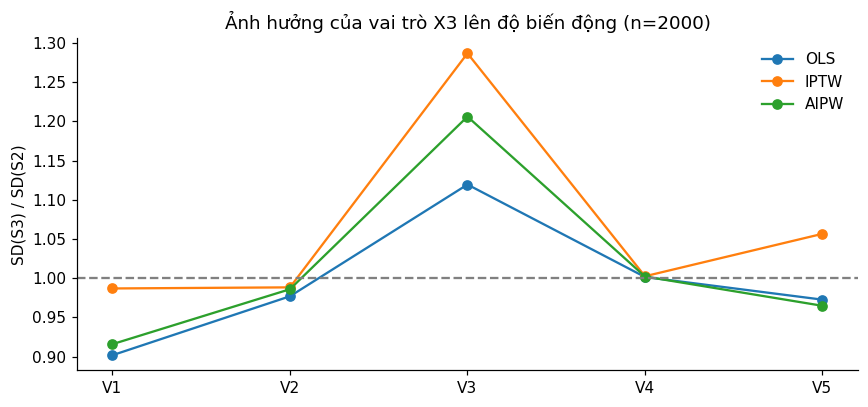

In [23]:
# So sánh SD S2/S3 theo vai trò X3, giữ cả bốn phương pháp.
tab = summary[summary.n == 2000].pivot(index=["scenario", "method"], columns="analysis", values="emp_sd")
tab["SD_S3_over_S2"] = tab.S3/tab.S2
display(tab.round(4))
fig, ax = plt.subplots(figsize=(8, 3.8))
for method in ("OLS", "IPTW", "AIPW"):
    group = tab.xs(method, level="method").dropna()
    ax.plot(group.index, group.SD_S3_over_S2, marker="o", label=method)
ax.axhline(1, color="gray", ls="--")
ax.set(ylabel="SD(S3) / SD(S2)", title="Ảnh hưởng của vai trò X3 lên độ biến động (n=2000)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULT_DIR / "X3_sd_ratio.png", bbox_inches="tight")
plt.show()


In [24]:
def conclude_added(summary, diagnostic_summary):
    ols = summary[(summary.n == 2000) & (summary.method == "OLS")].set_index(["scenario", "analysis"])
    diag = diagnostic_summary[diagnostic_summary.n == 2000].set_index(["scenario", "analysis"])
    ratios = {s: ols.loc[(s, "S3"), "emp_sd"]/ols.loc[(s, "S2"), "emp_sd"]
              for s in ("V2", "V3", "V4")}
    lines = ["## 9. Kết luận từ lần chạy",
             f"Với R={R}, bỏ X3 ở V1 có bias OLS {ols.loc[('V1','S2'), 'bias']:+.3f}; "
             f"thêm X3 có bias {ols.loc[('V1','S3'), 'bias']:+.3f}. "
             f"Max |SMD| trung bình sau IPTW trên biến S2 là {diag.loc[('V1','S2'), 'max_abs_smd_after']:.3f} "
             f"nhưng SMD X3 bị bỏ sót là {diag.loc[('V1','S2'), 'x3_smd_after']:.3f}. "
             "Balance tốt trên biến quan sát không chứng minh hết confounding.",
             "Tỉ lệ SD OLS S3/S2: " + "; ".join(f"{s}={v:.3f}" for s,v in ratios.items()) + ". "
             "Biến tiên lượng Y có lợi cho độ chính xác; biến chỉ tác động A có thể làm tăng phương sai "
             "và giảm ESS; biến noise có ít lợi ích.",
             f"V5 tương quan rho=0.7: bias S2 {ols.loc[('V5','S2'), 'bias']:+.3f}, "
             f"S3 {ols.loc[('V5','S3'), 'bias']:+.3f}. X1 chỉ mang một phần thông tin của X3.",
             "Số biến cần dựa trên vai trò trong DAG. Các kết luận này áp dụng cho DGP và estimator "
             "đang xét; chênh lệch nhỏ ở R=200 cần xác nhận R=1000. V7 hậu điều trị là tùy chọn chưa chạy."]
    return "\n\n".join(lines)
conclusion = conclude_added(summary, diagnostic_summary)
display(Markdown(conclusion))
(RESULT_DIR / "part_B_conclusions.md").write_text(conclusion, encoding="utf-8")


## 9. Kết luận từ lần chạy

Với R=200, bỏ X3 ở V1 có bias OLS +0.236; thêm X3 có bias +0.001. Max |SMD| trung bình sau IPTW trên biến S2 là 0.011 nhưng SMD X3 bị bỏ sót là 0.485. Balance tốt trên biến quan sát không chứng minh hết confounding.

Tỉ lệ SD OLS S3/S2: V2=0.977; V3=1.120; V4=1.002. Biến tiên lượng Y có lợi cho độ chính xác; biến chỉ tác động A có thể làm tăng phương sai và giảm ESS; biến noise có ít lợi ích.

V5 tương quan rho=0.7: bias S2 +0.121, S3 -0.001. X1 chỉ mang một phần thông tin của X3.

Số biến cần dựa trên vai trò trong DAG. Các kết luận này áp dụng cho DGP và estimator đang xét; chênh lệch nhỏ ở R=200 cần xác nhận R=1000. V7 hậu điều trị là tùy chọn chưa chạy.

693